C:\Users\World\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.9307 - loss: 0.2356 - val_accuracy: 0.9612 - val_loss: 0.1197
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9690 - loss: 0.0999 - val_accuracy: 0.9671 - val_loss: 0.1019
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9779 - loss: 0.0704 - val_accuracy: 0.9690 - val_loss: 0.1001
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9831 - loss: 0.0525 - val_accuracy: 0.9702 - val_loss: 0.1004
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9861 - loss: 0.0422 - val_accuracy: 0.9745 - val_loss: 0.0869
313/313 - 1s - 3ms/step - accuracy: 0.9745 - loss: 0.0869
Test Accuracy: 0.97
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
Predicted labels: [7 2 1 0 4]
True labels: [7 2 1 0 4]


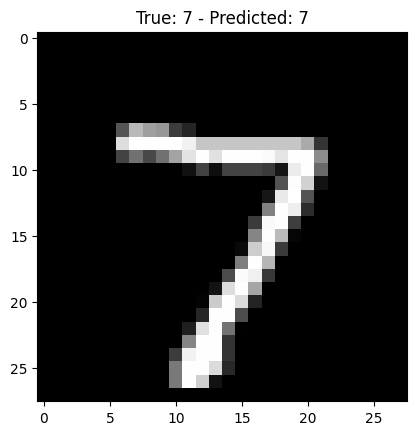

In [1]:
# Step 1: Import libraries
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt

# Step 2: Load dataset (MNIST handwritten digits)
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Normalize (scale) data between 0 and 1
x_train, x_test = x_train / 255.0, x_test / 255.0

# Step 3: Build Deep Learning Model
model = Sequential([
    Flatten(input_shape=(28,28)),         # Input Layer (28x28 image → 784 features)
    Dense(128, activation='relu'),        # Hidden Layer 1
    Dense(64, activation='relu'),         # Hidden Layer 2
    Dense(10, activation='softmax')       # Output Layer (10 classes: digits 0–9)
])

# Step 4: Compile Model
model.compile(optimizer='adam', 
              loss='sparse_categorical_crossentropy', 
              metrics=['accuracy'])

# Step 5: Train Model
history = model.fit(x_train, y_train, epochs=5, validation_data=(x_test, y_test))

# Step 6: Evaluate Model
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)
print(f"Test Accuracy: {test_acc:.2f}")

# Step 7: Make Predictions
predictions = model.predict(x_test[:5])
print("Predicted labels:", predictions.argmax(axis=1))
print("True labels:", y_test[:5])

# Step 8: Plot first test image
plt.imshow(x_test[0], cmap='gray')
plt.title(f"True: {y_test[0]} - Predicted: {predictions.argmax(axis=1)[0]}")
plt.show()
